# 2. La base de datos: estructura, tamaño, calidad y representatividad

Este capítulo caracteriza los datos **de entrenamiento** antes de analizarlos:
diccionario de variables, estructura, tamaño y entidades independientes, valores
faltantes (patrón y mecanismo), duplicados, valores atípicos e inconsistentes,
sesgos de muestreo y ética. La prueba no se mira.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

train = load_train()
y = train[TARGET]

## Diccionario de datos

Una fila por variable: nombre original, tipo, significado, unidad, valores,
faltantes y papel en el análisis. Las variables derivadas (calendario, ítems por
pedido y carga de los 7 días previos) se marcan como «(derivada)»; los componentes
seno/coseno se omiten porque son transformaciones de las de calendario.

In [2]:
dic = build_dictionary(train)
dic.to_csv(TABLES / "diccionario_datos.csv", index=False)
dic

,variable,nombre_original,tipo,significado,unidad,valores,únicos,faltantes,faltantes_%,papel
0,payment_type,Type,categórica nominal,"Tipo de transacción o medio de pago (DEBIT, TRANSFER, CASH, PAYMENT)",no aplica,"CASH, DEBIT, PAYMENT, TRANSFER",4,0,0.0,predictora candidata
1,days_shipping_real,Days for shipping (real),numérica discreta,Días reales entre la compra y el envío/entrega,días,"0, 1, 2, 3, 4, 5, 6",7,0,0.0,posterior al pedido; excluida (fuga)
2,days_shipping_scheduled,Days for shipment (scheduled),numérica discreta,Días de envío programados (promesa al cliente),días,"0, 1, 2, 4",4,0,0.0,predictora candidata
3,benefit_per_order,Benefit per order,numérica continua,Ganancia por ítem de pedido,USD,rango: -1375 a 250,18482,0,0.0,predictora candidata
4,sales_per_customer,Sales per customer,numérica continua,Venta total por cliente en la línea (igual a order_item_total),USD,rango: 7.49 a 500,1951,0,0.0,predictora candidata
...,...,...,...,...,...,...,...,...,...,...
57,order_weekend,(derivada),derivada temporal,1 si el pedido se hizo en sábado o domingo (derivada),no aplica,"0, 1",2,0,0.0,predictora candidata
58,order_afternoon,(derivada),derivada temporal,1 si el pedido se hizo a partir de las 12:00 (derivada),no aplica,"0, 1",2,0,0.0,predictora candidata
59,mode_x_daypart,(derivada),derivada categórica,Interacción modo de envío × jornada (AM/PM) del pedido (derivada),no aplica,"First Class | AM, First Class | PM, Same Day | AM, Same Day | PM, ...",8,0,0.0,predictora candidata
60,items_in_order,(derivada),derivada numérica,"Número de líneas del pedido (derivada, conocida al cerrar la compra)",ítems,"1, 2, 3, 4, 5",5,0,0.0,predictora candidata


## Estructura de los datos

- **Unidad de observación:** una **línea de pedido** (un producto dentro de un pedido).
- **Nivel de agregación:** transaccional (sin agregar). Las líneas se anidan en
  **pedidos** y los pedidos en **clientes**.
- **Tipo:** datos **transversales con marca de tiempo** (eventos irregulares en el
  tiempo, no una serie regular) y con **componente espacial** (latitud/longitud).
  Por eso es un problema de clasificación **espacio-temporal**: se analizan el
  tiempo (cap. 7) y el espacio (cap. 8) y la partición es cronológica.

,medida,valor
0,Líneas (filas) de entrenamiento,143.075
1,Variables originales,53
2,"Predictoras candidatas originales (sin objetivo, fuga, ids ni dato...",32
3,Relación n/p,4.471
4,Casos clase 1 (entrega tardía),78.549
5,Casos clase 0 (no tardía),64.526
6,Pedidos distintos,47.719
7,Clientes distintos,12.187
8,Líneas por pedido (media; máx.),"3,00; 5"
9,Pedidos por cliente (media; máx.),"3,92; 13"


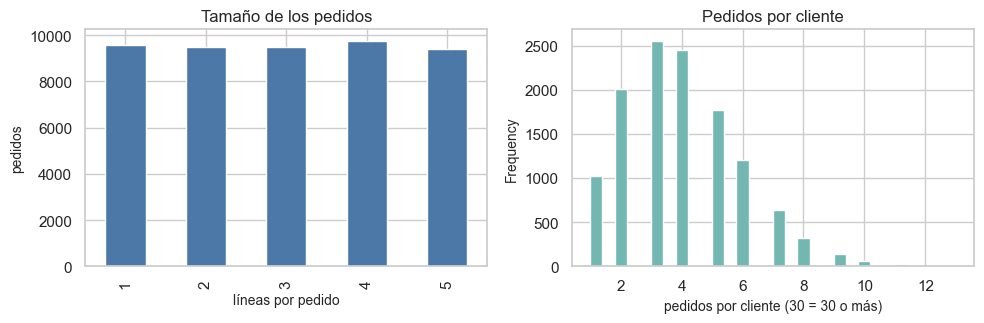

In [3]:
lineas_por_pedido = train.groupby(ORDER_COL).size()
pedidos_por_cliente = train.groupby(CUSTOMER_COL)[ORDER_COL].nunique()
etiqueta_unica = (train.groupby(ORDER_COL)[TARGET].nunique() == 1).mean()
predictoras = [c for c in RENAME.values() if c not in [TARGET] + LEAKAGE_COLS + ID_COLS + PII_COLS + [DATE_COL]]
n, p = len(train), len(predictoras)
tam = pd.DataFrame([
    ("Líneas (filas) de entrenamiento", es(n, 0)),
    ("Variables originales", len(RENAME)),
    ("Predictoras candidatas originales (sin objetivo, fuga, ids ni datos personales)", p),
    ("Relación n/p", es(n / p, 0)),
    ("Casos clase 1 (entrega tardía)", es(int(y.sum()), 0)),
    ("Casos clase 0 (no tardía)", es(int((1 - y).sum()), 0)),
    ("Pedidos distintos", es(train[ORDER_COL].nunique(), 0)),
    ("Clientes distintos", es(train[CUSTOMER_COL].nunique(), 0)),
    ("Líneas por pedido (media; máx.)", f"{es(lineas_por_pedido.mean(), 2)}; {lineas_por_pedido.max()}"),
    ("Pedidos por cliente (media; máx.)", f"{es(pedidos_por_cliente.mean(), 2)}; {pedidos_por_cliente.max()}"),
    ("Pedidos con la misma etiqueta en todas sus líneas", es(etiqueta_unica, 1, pct=True)),
    ("Ubicaciones (lat, lon) distintas", es(train[[LAT, LON]].drop_duplicates().shape[0], 0)),
], columns=["medida", "valor"])
tam.to_csv(TABLES / "tamano_muestra.csv", index=False)
display(tam)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
lineas_por_pedido.value_counts().sort_index().plot.bar(ax=axes[0], color="#4c78a8")
axes[0].set_xlabel("líneas por pedido"); axes[0].set_ylabel("pedidos"); axes[0].set_title("Tamaño de los pedidos")
pedidos_por_cliente.clip(upper=30).plot.hist(bins=30, ax=axes[1], color="#72b7b2")
axes[1].set_xlabel("pedidos por cliente (30 = 30 o más)"); axes[1].set_title("Pedidos por cliente")
plt.tight_layout(); save_figure(fig, "02_entidades.png"); plt.show()

**Interpretación.** El tamaño efectivo de la muestra está **entre el número de
pedidos y el de líneas**: todas las líneas de un pedido comparten la etiqueta
(100 %), así que no aportan evidencia independiente. Por eso (i) la partición
nunca separa un pedido, (ii) el bootstrap del capítulo 11 remuestrea **pedidos**
y no filas. Los clientes repiten compras, pero sus pedidos ocurren en fechas
distintas y el modelo no usa su identificador. Con n/p del orden de miles la
muestra es holgada para un modelo lineal.

## Valores faltantes: patrón

Se muestra el porcentaje por columna y la matriz de nulos (muestra de 2.000 filas
ordenadas en el tiempo).

,faltantes,faltantes_%
product_description,143075,100.00
order_zipcode,118235,82.64


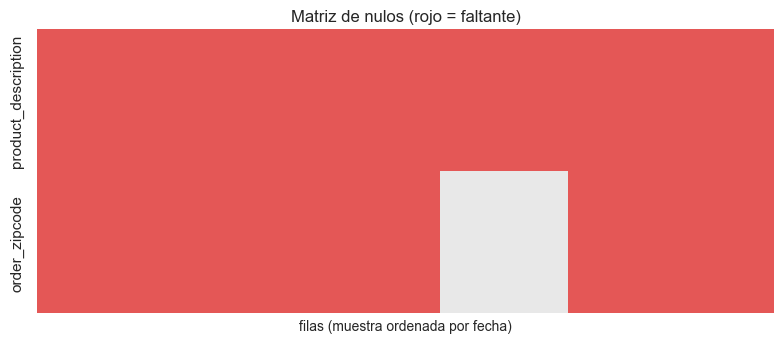

In [4]:
miss = train[list(RENAME.values())].isna().sum().to_frame("faltantes")
miss["faltantes_%"] = 100 * miss["faltantes"] / len(train)
miss = miss[miss["faltantes"] > 0].sort_values("faltantes_%", ascending=False)
miss.to_csv(TABLES / "faltantes_por_columna.csv")
display(miss.round(2))

sample = train.iloc[np.linspace(0, len(train) - 1, 2000).astype(int)]
cols_m = list(miss.index) + ["market", "order_country"]
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(sample[list(miss.index)].isna().T, cbar=False, cmap=["#e8e8e8", "#e45756"], ax=ax, xticklabels=False)
ax.set_xlabel("filas (muestra ordenada por fecha)"); ax.set_title("Matriz de nulos (rojo = faltante)")
plt.tight_layout(); save_figure(fig, "02_faltantes.png"); plt.show()

## Valores faltantes: mecanismo (MCAR, MAR o MNAR)

MCAR: la ausencia no depende de nada; MAR: depende de variables observadas; MNAR:
depende del propio valor no observado. Para cada indicador de ausencia se mide su
asociación con variables observadas (V de Cramér o rank-biserial) y se compara la
distribución entre filas completas e incompletas.

In [5]:
from scipy import stats
rows = []
for m in miss.index:
    ind = train[m].isna().astype(int)
    if ind.nunique() < 2:
        rows.append({"variable": m, "comparada_con": "—", "efecto": np.nan, "p_valor": np.nan,
                     "nota": "100 % faltante: no hay variación que comparar"})
        continue
    for o in ["market", "order_region", "shipping_mode", "customer_segment", TARGET]:
        v, chi2, pv = cramers_v(train[o], ind)
        rows.append({"variable": m, "comparada_con": o, "efecto": v, "p_valor": pv, "nota": "V de Cramér"})
    for o in ["sales", "order_item_quantity", "order_item_profit_ratio"]:
        a, b = train.loc[ind == 1, o], train.loc[ind == 0, o]
        u, pv = stats.mannwhitneyu(a, b)
        rows.append({"variable": m, "comparada_con": o, "efecto": abs(2 * u / (len(a) * len(b)) - 1), "p_valor": pv,
                     "nota": "|rank-biserial|"})
screen = pd.DataFrame(rows)
screen["p_fdr"] = fdr_bh(screen["p_valor"])
screen.to_csv(TABLES / "asociacion_faltantes.csv", index=False)
display(screen.round(4))
zip_por_mercado = train["order_zipcode"].notna().groupby(train["market"]).mean().rename("con_zipcode_%") * 100
display(zip_por_mercado.round(2).to_frame())

,variable,comparada_con,efecto,p_valor,nota,p_fdr
0,product_description,—,NaN,NaN,100 % faltante: no hay variación que comparar,NaN
1,order_zipcode,market,0.9772,0.0000,V de Cramér,0.0000
2,order_zipcode,order_region,0.9999,0.0000,V de Cramér,0.0000
3,order_zipcode,shipping_mode,0.0053,0.0717,V de Cramér,0.1583
4,order_zipcode,customer_segment,0.0046,0.0792,V de Cramér,0.1583
5,order_zipcode,late_delivery_risk,0.0000,0.6465,V de Cramér,0.6465
6,order_zipcode,sales,0.0026,0.5189,|rank-biserial|,0.5930
7,order_zipcode,order_item_quantity,0.0058,0.1206,|rank-biserial|,0.1930
8,order_zipcode,order_item_profit_ratio,0.0056,0.1638,|rank-biserial|,0.2184


,con_zipcode_%
market,
Africa,0.00
Europe,0.00
LATAM,0.00
Pacific Asia,0.00
USCA,96.28


**Interpretación.**

- `order_zipcode` falta en todos los pedidos fuera de **USCA** y casi nunca dentro de
  USCA (V de Cramér con `market` ≈ 1). La ausencia está **completamente explicada por
  una variable observada** → mecanismo **MAR estructural**: el código postal solo
  existe para destinos de EE. UU./Canadá; no es un dato «perdido» sino «no aplica».
  Su asociación con el objetivo es nula, y además la información geográfica ya está
  en `order_country`/`order_region`. **Decisión:** no se usa (capítulo 10).
- `product_description` está **100 % vacía**: no tiene información. **Decisión:** eliminar.
- No se aplica la prueba de Little porque no hay variables numéricas con faltantes
  parciales relevantes; la comparación por grupos es evidencia suficiente.

## Duplicados y casi-duplicados

Se buscan (i) filas duplicadas exactas ignorando el identificador de línea,
(ii) casi-duplicados: el mismo producto repetido en un mismo pedido, y
(iii) **columnas duplicadas** (una copia exacta de otra).

In [6]:
sin_id = train[list(RENAME.values())].drop(columns=[ITEM_COL])
dup_exactos = int(sin_id.duplicated().sum())
casi = int(train.duplicated(subset=[ORDER_COL, "product_card_id"]).sum())
col_dup = []
for a, b in DUPLICATE_PAIRS:
    col_dup.append({"columna": a, "copia_de": b, "coincidencia_%": 100 * float((train[a] == train[b]).mean())})
col_dup.append({"columna": "product_image", "copia_de": "product_name (1 a 1)",
                "coincidencia_%": 100 * float(train.groupby("product_name")["product_image"].nunique().eq(1).mean())})
col_dup.append({"columna": "days_shipping_scheduled", "copia_de": "shipping_mode (1 a 1)",
                "coincidencia_%": 100 * float(train.groupby("shipping_mode")["days_shipping_scheduled"].nunique().eq(1).mean())})
col_dup = pd.DataFrame(col_dup)
col_dup.to_csv(TABLES / "columnas_duplicadas.csv", index=False)
md_out(f"- Duplicados exactos (sin el id de línea): **{dup_exactos}**.\n"
       f"- Casi-duplicados (mismo producto dos veces en un pedido): **{es(casi, 0)}** líneas. Son compras legítimas registradas en "
       "líneas separadas y comparten etiqueta con su pedido, así que se conservan; el agrupamiento por pedido evita que inflen la evaluación.")
display(col_dup.round(2))

- Duplicados exactos (sin el id de línea): **0**.
- Casi-duplicados (mismo producto dos veces en un pedido): **17.248** líneas. Son compras legítimas registradas en líneas separadas y comparten etiqueta con su pedido, así que se conservan; el agrupamiento por pedido evita que inflen la evaluación.

,columna,copia_de,coincidencia_%
0,order_customer_id,customer_id,100.0
1,order_profit_per_order,benefit_per_order,100.0
2,order_item_total,sales_per_customer,100.0
3,order_item_product_price,product_price,100.0
4,product_category_id,category_id,100.0
5,order_item_cardprod_id,product_card_id,100.0
6,product_image,product_name (1 a 1),100.0
7,days_shipping_scheduled,shipping_mode (1 a 1),100.0


**Interpretación.** Seis columnas son **copias exactas** de otras, `product_image`
equivale al nombre del producto y `days_shipping_scheduled` está determinada
por `shipping_mode` (Standard = 4, Second = 2, First = 1, Same Day = 0 días). Mantener
ambas versiones introduce **multicolinealidad perfecta** (capítulo 5); en cada par se
conserva una sola columna (capítulo 10).

## Valores atípicos

Regla del IQR (fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]) en las numéricas originales.

In [7]:
num_orig = ["days_shipping_real", "days_shipping_scheduled", "benefit_per_order", "sales_per_customer",
            "order_item_discount", "order_item_discount_rate", "order_item_product_price", "order_item_profit_ratio",
            "order_item_quantity", "sales", LAT, LON]
res_num = numeric_summary(train[num_orig])
res_num.to_csv(TABLES / "atipicos_numericas.csv")
display(res_num[["media", "mediana", "mínimo", "máximo", "asimetría", "outliers_IQR_%"]].round(3))

,media,mediana,mínimo,máximo,asimetría,outliers_IQR_%
days_shipping_real,3.499,3.000,0.000,6.000,0.082,0.000
days_shipping_scheduled,2.932,4.000,0.000,4.000,-0.732,0.000
benefit_per_order,21.156,31.120,-1374.860,249.980,-3.532,10.547
sales_per_customer,177.011,159.990,7.490,499.950,0.706,0.714
order_item_discount,19.974,14.000,0.000,124.990,1.558,4.440
order_item_discount_rate,0.102,0.100,0.000,0.250,0.341,0.000
order_item_product_price,131.294,59.990,9.990,399.980,1.267,0.000
order_item_profit_ratio,0.120,0.270,-2.750,0.500,-2.886,9.633
order_item_quantity,2.204,1.000,1.000,5.000,0.782,0.000
sales,196.985,179.970,9.990,499.950,0.658,0.000


**Interpretación.** Los valores extremos de ventas y precios corresponden a
**productos caros reales** (por ejemplo, equipos de gimnasia o electrónica), no a
errores de captura; los de ganancia negativa son líneas vendidas con pérdida
(margen de hasta −275 %), también plausibles en una tienda con descuentos. Se
conservan y la asimetría se trata con `log1p` en el Pipeline (capítulo 10).

## Valores imposibles o inconsistentes

Comprobaciones de rangos, unidades, coherencia aritmética entre columnas y
categorías mal escritas.

In [8]:
tol = 0.05
checks = [
    ("Latitud fuera de [-90, 90] o longitud fuera de [-180, 180]", int((~train[LAT].between(-90, 90) | ~train[LON].between(-180, 180)).sum())),
    ("Coordenadas (0, 0)", int(((train[LAT] == 0) & (train[LON] == 0)).sum())),
    ("Precio <= 0", int((train["product_price"] <= 0).sum())),
    ("Cantidad <= 0", int((train["order_item_quantity"] <= 0).sum())),
    ("Tasa de descuento fuera de [0, 1]", int((~train["order_item_discount_rate"].between(0, 1)).sum())),
    ("sales ≠ precio × cantidad", int(((train["sales"] - train["order_item_product_price"] * train["order_item_quantity"]).abs() > tol).sum())),
    ("order_item_total ≠ sales − descuento", int(((train["order_item_total"] - (train["sales"] - train["order_item_discount"])).abs() > tol).sum())),
    ("Fecha de despacho anterior a la del pedido", int((train["shipping_date"] < train[DATE_COL]).sum())),
    ("Días reales ≠ días de calendario entre pedido y despacho", int(((train["shipping_date"].dt.normalize() - train[DATE_COL].dt.normalize()).dt.days != train["days_shipping_real"]).sum())),
    ("Tardía según días reales > programados pero etiqueta 0", int(((train["days_shipping_real"] > train["days_shipping_scheduled"]) & (y == 0)).sum())),
    ("Etiqueta 1 con días reales <= programados", int(((train["days_shipping_real"] <= train["days_shipping_scheduled"]) & (y == 1)).sum())),
    ("product_status constante", int(train["product_status"].nunique() == 1)),
    ("customer_email / password enmascarados (un solo valor)", int(train["customer_email"].nunique() == 1 and train["customer_password"].nunique() == 1)),
]
checks = pd.DataFrame(checks, columns=["comprobación", "casos"])
checks.to_csv(TABLES / "valores_inconsistentes.csv", index=False)
display(checks)
inc = train[(train["days_shipping_real"] > train["days_shipping_scheduled"]) & (y == 0)]
display(pd.crosstab(inc["delivery_status"], inc["order_status"]))
md_out("Nombres en dos idiomas: `customer_country` usa «EE. UU.» y «Puerto Rico» (español), y `order_country` mezcla nombres en español "
       f"({', '.join(train['order_country'].value_counts().index[:5])}). No son errores de codificación sino de convención; se tratan como categorías.")

,comprobación,casos
0,"Latitud fuera de [-90, 90] o longitud fuera de [-180, 180]",0
1,"Coordenadas (0, 0)",0
2,Precio <= 0,0
3,Cantidad <= 0,0
4,"Tasa de descuento fuera de [0, 1]",0
5,sales ≠ precio × cantidad,0
6,order_item_total ≠ sales − descuento,0
7,Fecha de despacho anterior a la del pedido,0
8,Días reales ≠ días de calendario entre pedido y despacho,0
9,Tardía según días reales > programados pero etiqueta 0,3362


order_status,CANCELED,SUSPECTED_FRAUD
delivery_status,,
Shipping canceled,1578,1784


Nombres en dos idiomas: `customer_country` usa «EE. UU.» y «Puerto Rico» (español), y `order_country` mezcla nombres en español (Estados Unidos, México, Francia, Australia, Brasil). No son errores de codificación sino de convención; se tratan como categorías.

**Interpretación.**

- `days_shipping_real` coincide con la diferencia **en días de calendario** entre el pedido y el
  despacho (no en horas: un envío de 12 horas que cruza la medianoche cuenta 1 día).
- La aritmética entre precio, cantidad, venta y total es coherente y no hay
  coordenadas imposibles ni (0, 0).
- **Inconsistencia relevante:** hay líneas con días reales mayores que los
  programados pero etiqueta 0. Todas son pedidos **cancelados o sospechosos de
  fraude** (`delivery_status = Shipping canceled`): la etiqueta 0 no significa «llegó a tiempo»,
  sino «no se entregó». Esta población se discute como riesgo de fuga en el
  capítulo 9.
- `product_status` es constante y `customer_email`/`customer_password` están
  enmascarados: no aportan información.

## Sesgos de muestreo y representatividad

- **Datos simulados de una empresa ficticia.** Los autores construyeron el
  conjunto con fines académicos; las relaciones pueden ser más simples (o más
  aleatorias) que en una cadena de suministro real. Las conclusiones aplican a
  DataCo, no a la logística en general.
- **Clientes solo en EE. UU. y Puerto Rico** (`customer_country`), pero pedidos con
  destino en 164 países (`order_country`). La ubicación del cliente/tienda y el destino
  son, por tanto, dimensiones distintas; las coordenadas no describen el destino.
- **Cambio de régimen al final del periodo** (desde octubre de 2017 hay un solo
  producto por pedido y se reduce el catálogo; capítulo 7). Afecta a la prueba y se
  evalúa como deriva.
- **Un único canal y catálogo** (artículos deportivos, ropa, electrónica): no
  representa otros sectores ni otros transportistas.

## Consideraciones éticas

- **Datos personales:** nombre, apellido, dirección y código postal del cliente.
  Aunque la empresa sea ficticia, se tratan como si fueran reales: se excluyen del
  modelo, no se muestran en el libro y no se combinan entre sí.
- **Reidentificación:** las coordenadas son **una por cliente** y, junto con fecha y
  hora exactas de cada pedido, podrían permitir reidentificar a una persona en un
  conjunto real. En el análisis espacial (capítulo 8) se trabaja con **celdas de 1°**
  agregadas, no con puntos individuales etiquetados.
- **Uso del modelo:** priorizar pedidos por riesgo no debe traducirse en peor
  servicio para mercados o segmentos con más retrasos; el capítulo 11 revisa el
  desempeño por mercado y segmento.